In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns 

In [9]:
data = pd.read_csv("housing.csv")
data

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND


In [10]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


In [11]:
data.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [12]:
from sklearn.model_selection import train_test_split

X = data.drop(["median_house_value"], axis=1)
y = data["median_house_value"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.2, random_state = 42)

In [13]:
print(X_train.shape)
print(X_test.shape)

(16512, 9)
(4128, 9)


In [14]:
X_test.isnull().sum()


longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
ocean_proximity         0
dtype: int64

In [15]:
# Filling the missing values in total bedroom with the mean value
X_train["total_bedrooms"] = X_train["total_bedrooms"].fillna(X_train["total_bedrooms"].mean())
X_test["total_bedrooms"] = X_test["total_bedrooms"].fillna(X_train["total_bedrooms"].mean())
data.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [16]:
X_train.isnull().sum()

longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
ocean_proximity       0
dtype: int64

# **Feature Engineering**

In [17]:
X_train["rooms_per_household"] = X_train["total_rooms"] / X_train["households"]
X_train["bedrooms_ratio"] = X_train["total_bedrooms"] / X_train["total_rooms"]

In [18]:
X_test["rooms_per_household"] = X_test["total_rooms"] / X_test["households"]
X_test["bedrooms_ratio"] = X_test["total_bedrooms"] / X_test["total_rooms"]

In [19]:
X_test.columns

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'ocean_proximity', 'rooms_per_household', 'bedrooms_ratio'],
      dtype='str')

# **Feature Encoding**

In [20]:
data.ocean_proximity.value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

## **Train Set Encoding**

In [21]:
train_dummies = pd.get_dummies(X_train["ocean_proximity"])
X_train = X_train.join(train_dummies)
X_train = X_train.drop("ocean_proximity", axis=1)

In [22]:
X_train.columns

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'rooms_per_household', 'bedrooms_ratio', '<1H OCEAN', 'INLAND',
       'ISLAND', 'NEAR BAY', 'NEAR OCEAN'],
      dtype='str')

In [23]:
dummy_columns = ["<1H OCEAN", "INLAND", "ISLAND", "NEAR BAY", "NEAR OCEAN"]

X_train[dummy_columns] = X_train[dummy_columns].astype(int)

## **Test Set Encoding**

In [24]:
X_test["ocean_proximity"].value_counts()

ocean_proximity
<1H OCEAN     1795
INLAND        1324
NEAR OCEAN     572
NEAR BAY       436
ISLAND           1
Name: count, dtype: int64

In [25]:
test_dummies = pd.get_dummies(X_test["ocean_proximity"])
X_test = X_test.join(test_dummies)
X_test = X_test.drop("ocean_proximity", axis=1)

In [26]:
X_test.columns

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'rooms_per_household', 'bedrooms_ratio', '<1H OCEAN', 'INLAND',
       'ISLAND', 'NEAR BAY', 'NEAR OCEAN'],
      dtype='str')

In [27]:
X_test[dummy_columns] = X_test[dummy_columns].astype(int)

In [28]:

X_test.columns

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'rooms_per_household', 'bedrooms_ratio', '<1H OCEAN', 'INLAND',
       'ISLAND', 'NEAR BAY', 'NEAR OCEAN'],
      dtype='str')

In [29]:
X_test = X_test[X_train.columns]

In [30]:
X_train.columns.equals(X_test.columns)

True

<Axes: >

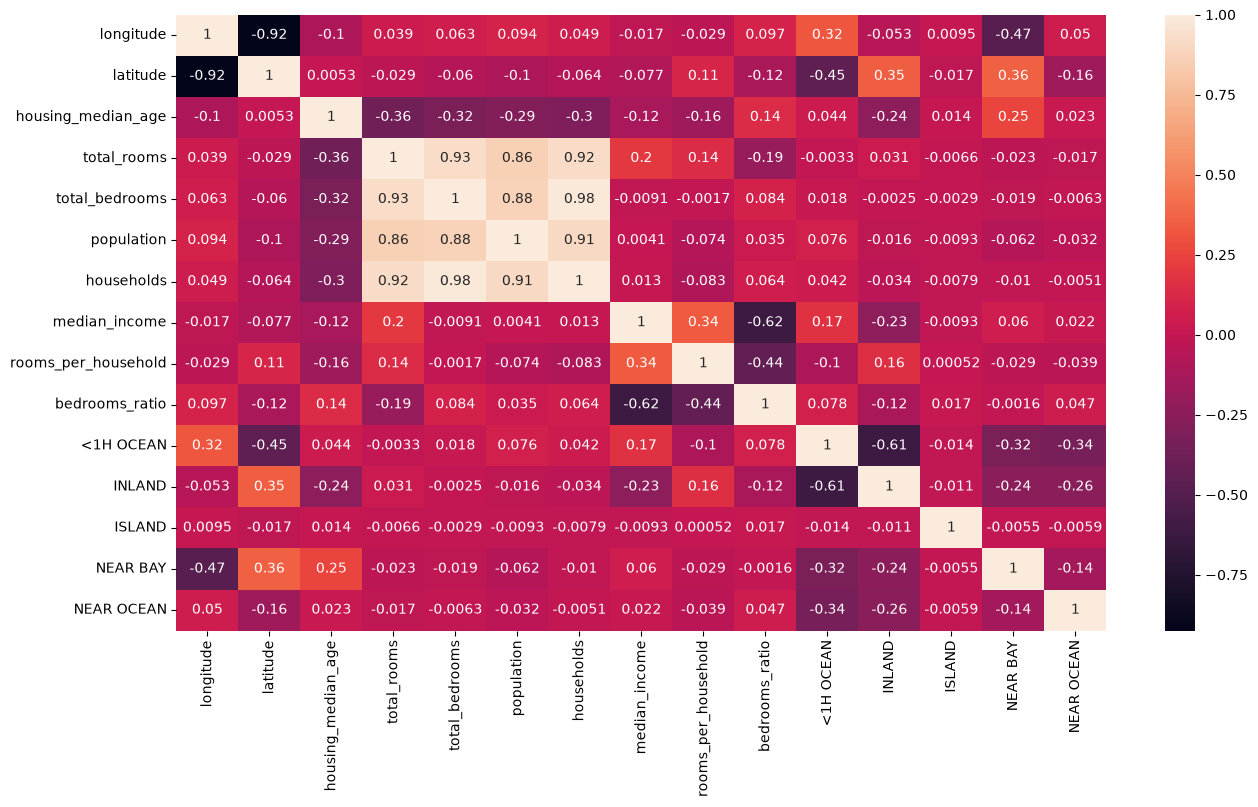

In [31]:
plt.figure(figsize=(15,8))
sns.heatmap(X_train.corr(), annot= True) #, #cmap= "YlGnBu")

In [32]:
X_train.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,rooms_per_household,bedrooms_ratio,<1H OCEAN,INLAND,ISLAND,NEAR BAY,NEAR OCEAN
14196,-117.03,32.71,33.0,3126.0,627.0,2300.0,623.0,3.2596,5.017657,0.200576,0,0,0,0,1
8267,-118.16,33.77,49.0,3382.0,787.0,1314.0,756.0,3.8125,4.473545,0.232703,0,0,0,0,1
17445,-120.48,34.66,4.0,1897.0,331.0,915.0,336.0,4.1563,5.645833,0.174486,0,0,0,0,1
14265,-117.11,32.69,36.0,1421.0,367.0,1418.0,355.0,1.9425,4.002817,0.258269,0,0,0,0,1
2271,-119.80,36.78,43.0,2382.0,431.0,874.0,380.0,3.5542,6.268421,0.180940,0,1,0,0,0


# **Feature Scaling**

In [33]:
from sklearn.preprocessing import StandardScaler

In [34]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

In [35]:
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# **MODEL TRAINING**

## Linear Model


In [36]:
from sklearn.linear_model import LinearRegression

reg = LinearRegression()

In [37]:
reg.fit(X_train_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](15,)","[-56220.42,-56551.23, 14143.31,..., 2213.44, 1907.28, 4828.11]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.072e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,15
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(14)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](15,)","[254.5 ,207.96,182.12,..., 20.53, 13.56, 0. ]"


In [38]:
y_pred_linear = reg.predict(X_test_scaled)


In [39]:
reg.score(X_test_scaled, y_test)

0.5747221639381216

In [40]:
reg.score(X_train_scaled, y_train)

0.6581805562795925

# Using GridSearchCv to Determine Alpha Value

In [41]:
# Using GridSearchCV
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import Ridge

ridge = Ridge()

param_grid = {
    "alpha": [0.01, 0.1, 1, 10, 100]
}

ridge_grid_search = GridSearchCV(
    ridge,
    param_grid,
    cv=5,
    scoring="neg_mean_squared_error",
    return_train_score=True
)

ridge_grid_search.fit(X_train_scaled, y_train)

print(ridge_grid_search.best_params_)
print(np.sqrt(-ridge_grid_search.best_score_))








{'alpha': 10}
67818.05691770732


In [42]:
lasso = Lasso(max_iter=10000)
param_grid = {
    "alpha": [0.01, 0.1, 1, 10, 100]
}

lasso_grid_search = GridSearchCV(
    lasso,
    param_grid,
    cv=5,
    scoring="neg_mean_squared_error",
    return_train_score=True
)

lasso_grid_search.fit(X_train_scaled, y_train)

print("Best Lasso alpha:", lasso_grid_search.best_params_)

print("Best Lasso CV RMSE:", np.sqrt(-lasso_grid_search.best_score_))

NameError: name 'Lasso' is not defined

In [ ]:
best_ridge = ridge_grid_search.best_estimator_
best_lasso = lasso_grid_search.best_estimator_

y_pred_ridge = best_ridge.predict(X_test_scaled)
y_pred_lasso = best_lasso.predict(X_test_scaled)

##  Ridge Regression


In [47]:
from sklearn.linear_model import Ridge

ridge_model = Ridge(alpha=10)


In [48]:
ridge_model.fit(X_train_scaled, y_train)

,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",10
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' t

In [49]:
ridge_model.score(X_test_scaled, y_test)

0.5751542172292522

In [50]:
ridge_model.score(X_train_scaled, y_train)

0.6581724670626775

In [51]:
y_pred_ridge = ridge_model.predict(X_test_scaled)

## Lasso Regression

In [52]:
from sklearn.linear_model import Lasso

In [53]:
lasso_model = Lasso(alpha=100)

In [54]:
lasso_model.fit(X_train_scaled, y_train)

,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",100
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'
Name,Type,Value


In [55]:
lasso_model.score(X_test_scaled, y_test)

0.5773648776553226

In [56]:
y_pred_lasso = lasso_model.predict(X_test_scaled)

In [57]:
y_pred_lasso = lasso_model.predict(X_test_scaled)

# **Metrics Calculation**

## **Mean Absolute Error**

In [58]:
from sklearn.metrics import mean_absolute_error

mae_linear = mean_absolute_error(y_test, y_pred_linear)
mae_ridge = mean_absolute_error(y_test, y_pred_ridge)
mae_lasso = mean_absolute_error(y_test, y_pred_lasso)

print("Linear MAE: ", mae_linear)
print("Ridge MAE: ", mae_ridge)
print("Lasso MAE: ", mae_lasso)

Linear MAE:  51484.64209212395
Ridge MAE:  51478.013670703585
Lasso MAE:  51411.52559439887


# **Root Mean Squared Error**

In [ ]:
from sklearn.metrics import mean_squared_error
import numpy as np 

rmse_linear = np.sqrt(mean_squared_error(y_test, y_pred_linear))
rmse_ridge = np.sqrt(mean_squared_error(y_test, y_pred_ridge))
rmse_lasso = np.sqrt(mean_squared_error(y_test, y_pred_lasso))

print("Linear Regression RMSE: ", round(rmse_linear, 2))
print("Ridge Regression RMSE: ", round(rmse_ridge, 2))
print("Lasso Regression RMSE: ", round(rmse_lasso, 2))

Linear Regression RMSE:  74651.72
Ridge Regression RMSE:  74647.8
Lasso Regression RMSE:  74649.46


# **R2**

In [ ]:
from sklearn.metrics import r2_score

r2_linear = r2_score(y_test, y_pred_linear)
r2_ridge = r2_score(y_test, y_pred_ridge)
r2_lasso = r2_score(y_test, y_pred_lasso)

print("Linear Regression R2: ", round(r2_linear, 2))
print("Ridge Regression R2: ", round(r2_ridge, 2))
print("Lasso Regression R2: ", round(r2_lasso, 2))  

Linear Regression R2:  0.57
Ridge Regression R2:  0.57
Lasso Regression R2:  0.57


In [ ]:
results_df = pd.DataFrame({
    
    "Model" : [
        "Linear Regression",
        "Ridge Regression",
        "Lasso Regression"
    ],

    "MAE":[
        mae_linear,
        mae_ridge,
        mae_lasso
    ],

    "RMSE":[
        rmse_linear,
        rmse_ridge,
        rmse_lasso
    ],

    "R2_Score": [ 
        r2_linear,
        r2_ridge,
        r2_lasso
    ]
})

display(results_df.round(3))

,Model,MAE,RMSE,R2_Score
0,Linear Regression,51484.642,74651.718,0.575
1,Ridge Regression,51483.971,74647.803,0.575
2,Lasso Regression,51483.976,74649.461,0.575


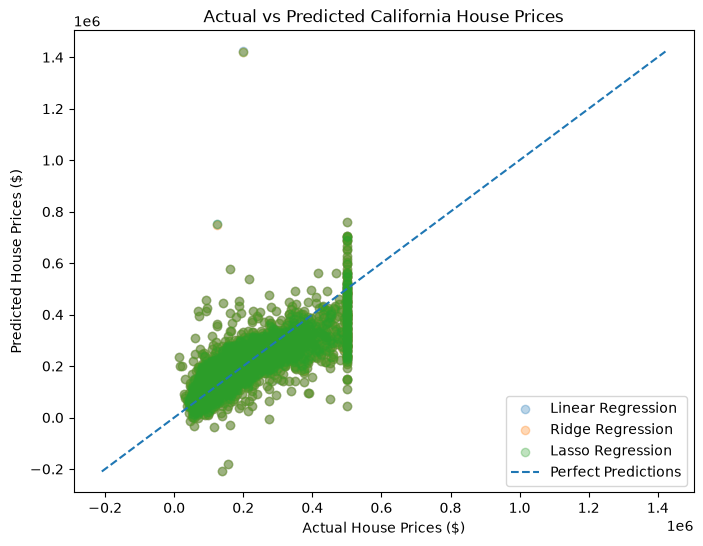

In [ ]:

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_linear, alpha=0.3, label="Linear Regression")
plt.scatter(y_test, y_pred_ridge, alpha=0.3, label="Ridge Regression")
plt.scatter(y_test, y_pred_lasso, alpha=0.3, label="Lasso Regression")

min_price = min(y_test.min(), y_pred_linear.min(),
                y_pred_ridge.min(), y_pred_lasso.min())

max_price = max(y_test.max(), y_pred_linear.max(),
                y_pred_ridge.max(), y_pred_lasso.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--",
    label="Perfect Predictions"
)

plt.xlabel("Actual House Prices ($)")
plt.ylabel("Predicted House Prices ($)")
plt.title("Actual vs Predicted California House Prices")
plt.legend()
plt.show()


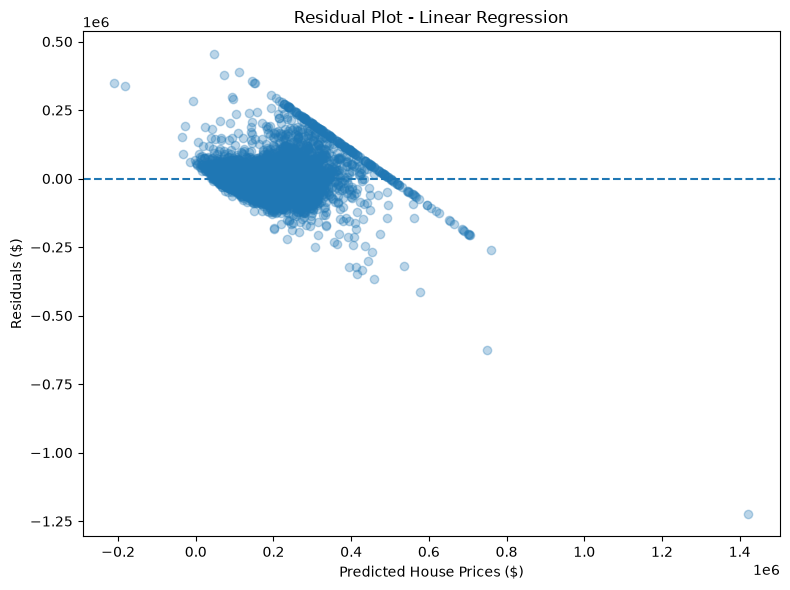

In [ ]:

residuals_linear = y_test - y_pred_linear

plt.figure(figsize=(8, 6))

plt.scatter(y_pred_linear, residuals_linear, alpha=0.3)
plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted House Prices ($)")
plt.ylabel("Residuals ($)")
plt.title("Residual Plot - Linear Regression")

plt.tight_layout()
plt.show()


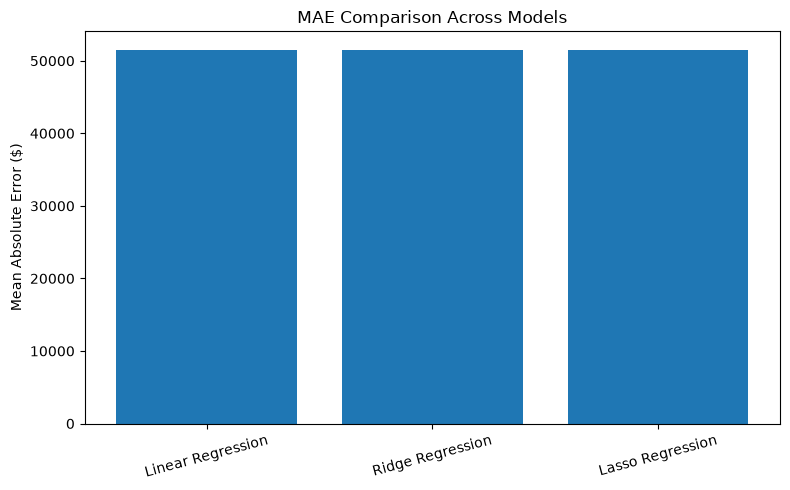

In [ ]:

plt.figure(figsize=(8, 5))

plt.bar(
    ["Linear Regression", "Ridge Regression", "Lasso Regression"],
    [mae_linear, mae_ridge, mae_lasso]
)

plt.ylabel("Mean Absolute Error ($)")
plt.title("MAE Comparison Across Models")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


In [ ]:

best_model_name = results_df.loc[
    results_df["RMSE"].idxmin(), "Model"
]

print("Best model based on RMSE:", best_model_name)


Best model based on RMSE: Ridge Regression


# Residual distribution curves

In [59]:
residuals_linear = y_test - y_pred_linear
residuals_ridge = y_test - y_pred_ridge
residuals_lasso = y_test - y_pred_lasso

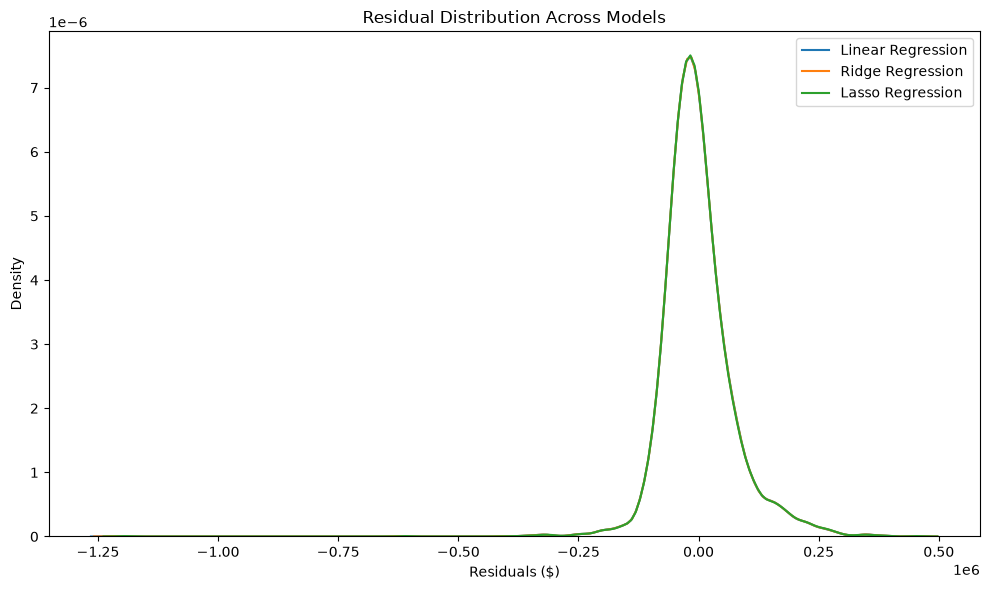

In [60]:
plt.figure(figsize=(10, 6))

sns.kdeplot(residuals_linear, label="Linear Regression")
sns.kdeplot(residuals_ridge, label="Ridge Regression")
sns.kdeplot(residuals_lasso, label="Lasso Regression")

plt.xlabel("Residuals ($)")
plt.ylabel("Density")
plt.title("Residual Distribution Across Models")
plt.legend()
plt.tight_layout()
plt.show()

## **Project Conclusion**

This project focused on developing a machine learning model to predict median house values using the California Housing Dataset.

The dataset was explored and prepared by handling missing values, performing feature engineering, encoding categorical variables, and standardizing numerical features.

Three regression models were implemented and evaluated: Linear Regression, Ridge Regression, and Lasso Regression. GridSearchCV with 5-fold cross-validation was used to identify suitable regularization parameters (alpha) for the Ridge and Lasso models.

The models were evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R² Score. Actual-versus-predicted plots and residual visualizations were also used to examine their prediction performance.

The results showed that the three models achieved relatively similar performance, with Ridge Regression recording a slightly higher R² score than Lasso Regression in the observed test results. However, the difference was very small, so Ridge cannot be considered significantly better based on this result alone.

Overall, this project demonstrates how machine learning regression techniques can be applied to estimate house values based on property characteristics. The model could serve as a decision-support tool for real estate professionals, although further testing with more recent and locally relevant property data would be necessary before real-world deployment.